In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [16]:
# 1. Load California Housing Dataset
housing = fetch_california_housing()
df = pd.DataFrame(housing.data, columns=housing.feature_names)
df['MedHouseVal'] = housing.target
print("Shape:", df.shape)
print(df.head())



Shape: (20640, 9)
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [17]:
# 2. Feature Engineering - Interaction Features (As per task)
df['Rooms_per_Household'] = df['AveRooms'] / df['AveOccup']
df['Bedrooms_per_Room'] = df['AveBedrms'] / df['AveRooms']
df['Population_per_Household'] = df['Population'] / df['AveOccup']
print("\nAdded Interaction Features:", df[['Rooms_per_Household','Bedrooms_per_Room']].head())



Added Interaction Features:    Rooms_per_Household  Bedrooms_per_Room
0             2.732919           0.146591
1             2.956685           0.155797
2             2.957661           0.129516
3             2.283154           0.184458
4             2.879646           0.172096


In [18]:
# 3. Check Nulls & Impute (Task requirement)
print("\nNulls:\n", df.isnull().sum())
# California dataset has no nulls, but we add imputation code for report
df = df.fillna(df.median())




Nulls:
 MedInc                      0
HouseAge                    0
AveRooms                    0
AveBedrms                   0
Population                  0
AveOccup                    0
Latitude                    0
Longitude                   0
MedHouseVal                 0
Rooms_per_Household         0
Bedrooms_per_Room           0
Population_per_Household    0
dtype: int64


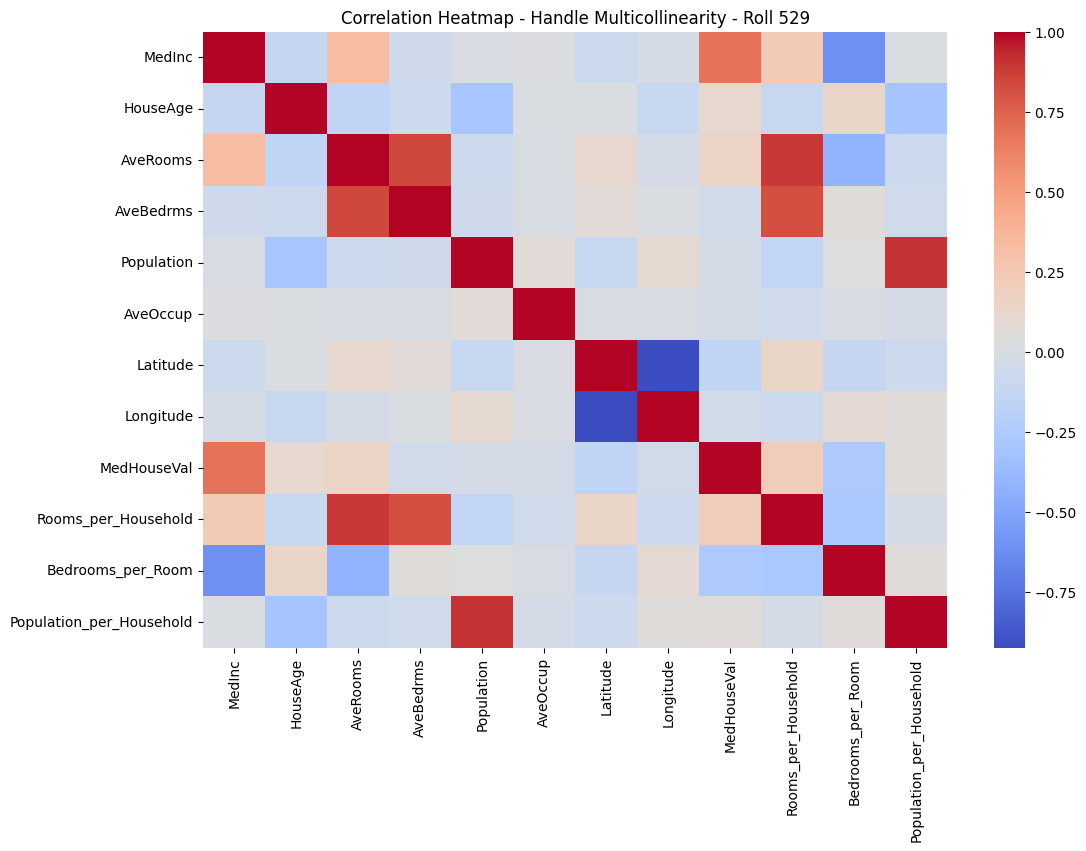

In [19]:
# 4. Correlation Heatmap & Multicollinearity Check
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), cmap='coolwarm')
plt.title("Correlation Heatmap - Handle Multicollinearity - Roll 529")
plt.show()


In [20]:
# 5. X,y Split
X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [21]:
# 6. Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [22]:
# 7. OLS - Ordinary Least Squares
ols = LinearRegression()
ols.fit(X_train_scaled, y_train)
y_pred_ols = ols.predict(X_test_scaled)



In [23]:
# 8. Ridge with GridSearchCV (L2)
ridge_params = {'alpha': [0.01, 0.1, 1.0, 10.0, 100.0]}
ridge_grid = GridSearchCV(Ridge(), ridge_params, cv=5, scoring='neg_mean_squared_error')
ridge_grid.fit(X_train_scaled, y_train)
y_pred_ridge = ridge_grid.predict(X_test_scaled)
print(f"\nBest Ridge Alpha: {ridge_grid.best_params_}")




Best Ridge Alpha: {'alpha': 10.0}


In [24]:
 # 9. Lasso with GridSearchCV (L1)
lasso_params = {'alpha': [0.0001, 0.001, 0.01, 0.1, 1.0]}
lasso_grid = GridSearchCV(Lasso(max_iter=5000), lasso_params, cv=5, scoring='neg_mean_squared_error')
lasso_grid.fit(X_train_scaled, y_train)
y_pred_lasso = lasso_grid.predict(X_test_scaled)
print(f"Best Lasso Alpha: {lasso_grid.best_params_}")


Best Lasso Alpha: {'alpha': 0.001}


In [25]:
# 10. Metrics Comparison - RMSE, MAE, R2
def get_metrics(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred)), mean_absolute_error(y_true, y_pred), r2_score(y_true, y_pred)

results = []
for name, y_pred in [("OLS (Ordinary Least Squares)", y_pred_ols), ("Ridge (L2)", y_pred_ridge), ("Lasso (L1)", y_pred_lasso)]:
    rmse, mae, r2 = get_metrics(y_test, y_pred)
    results.append([name, rmse, mae, r2])
    print(f"{name} -> RMSE: {rmse:.4f}, MAE: {mae:.4f}, R2: {r2:.4f}")
results_df = pd.DataFrame(results, columns=['Model', 'RMSE', 'MAE', 'R2 Score'])
print("\nFinal Comparison Table:\n", results_df)




OLS (Ordinary Least Squares) -> RMSE: 0.6738, MAE: 0.4874, R2: 0.6535
Ridge (L2) -> RMSE: 0.6739, MAE: 0.4874, R2: 0.6535
Lasso (L1) -> RMSE: 0.6740, MAE: 0.4874, R2: 0.6533

Final Comparison Table:
                           Model      RMSE       MAE  R2 Score
0  OLS (Ordinary Least Squares)  0.673817  0.487439  0.653521
1                    Ridge (L2)  0.673852  0.487408  0.653485
2                    Lasso (L1)  0.673984  0.487436  0.653349


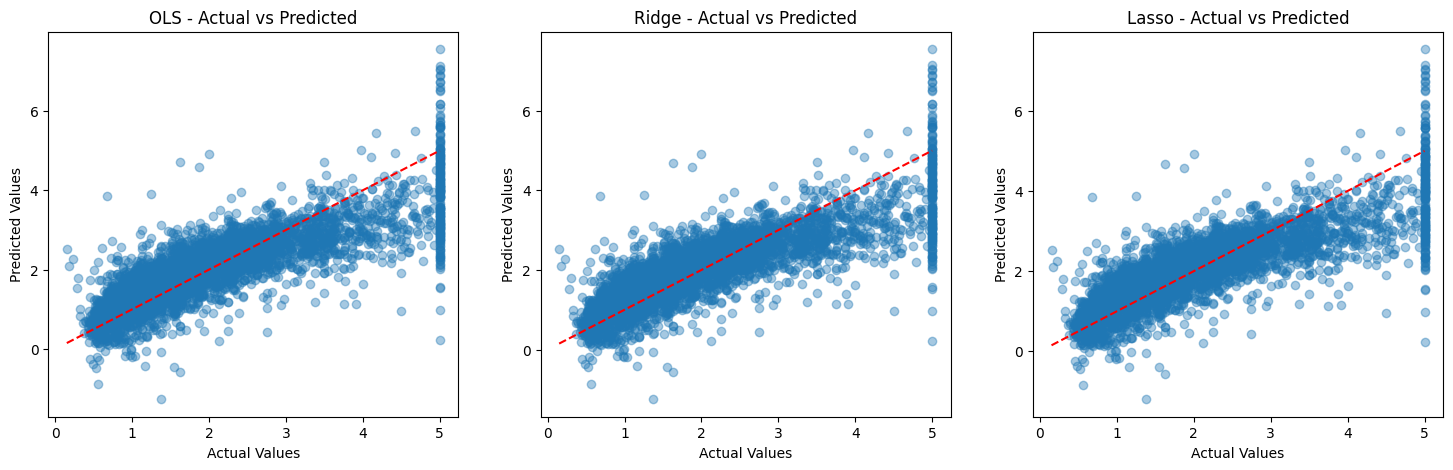

In [26]:
# 11. Predicted vs Actual Plot
fig, axes = plt.subplots(1,3, figsize=(18,5))
for ax, (name, y_pred) in zip(axes, [("OLS", y_pred_ols), ("Ridge", y_pred_ridge), ("Lasso", y_pred_lasso)]):
    ax.scatter(y_test, y_pred, alpha=0.4)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
    ax.set_xlabel("Actual Values")
    ax.set_ylabel("Predicted Values")
    ax.set_title(f"{name} - Actual vs Predicted")
plt.show()


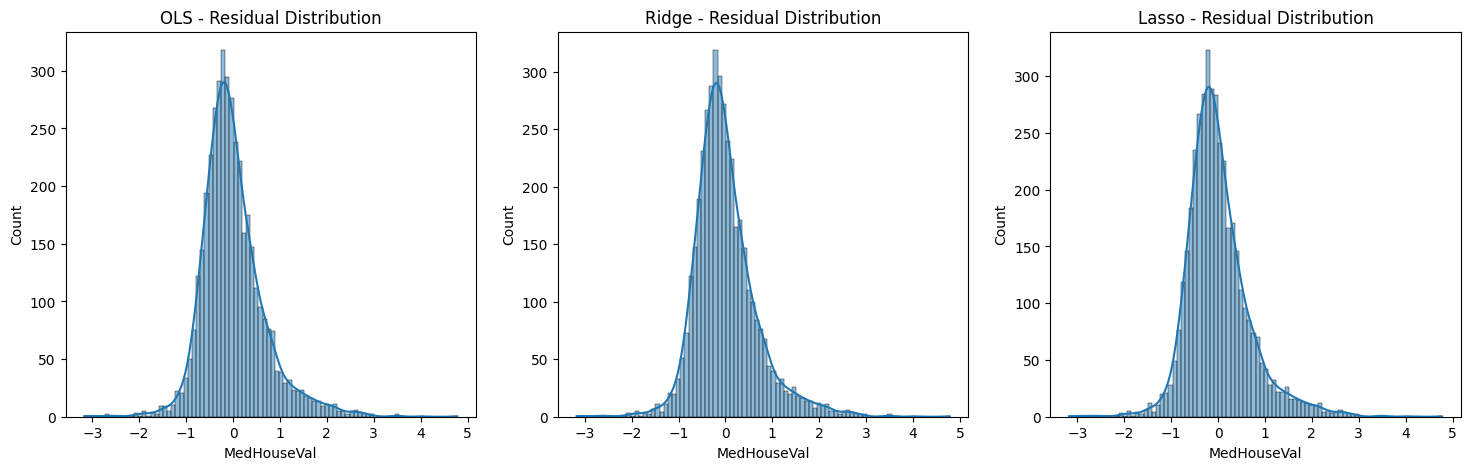

In [27]:
# 12. Residual Distribution Curves (Task Requirement)
fig, axes = plt.subplots(1,3, figsize=(18,5))
for ax, (name, y_pred) in zip(axes, [("OLS", y_pred_ols), ("Ridge", y_pred_ridge), ("Lasso", y_pred_lasso)]):
    residuals = y_test - y_pred
    sns.histplot(residuals, kde=True, ax=ax)
    ax.set_title(f"{name} - Residual Distribution")
plt.show()